# Customer Retention Analysis

An analysis of 7,043 telecom customers to find out who is leaving, when they leave, and which group to target first to cut churn.

**Business question:** the company is losing more than a quarter of its customers. Where is the churn concentrated, and where would a retention effort have the most impact?

**Tools:** SQL (DuckDB) and Python (pandas, matplotlib). Every query runs on the real data; the results below are the actual output.

To run it yourself, click **Runtime → Run all** in Google Colab.

## 1. Setup

In [1]:
# DuckDB runs SQL directly in Python, with no database server to install
%pip install -q duckdb

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
con = duckdb.connect()

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


## 2. Load and clean the data

The data is IBM's free Telco Customer Churn sample dataset. A few cleanup steps happen as it loads:

- Yes/No columns become true/false flags, and churn becomes 1/0, so the churn rate is just its average.
- `TotalCharges` is blank for brand-new customers. Those blanks become missing values instead of zero, so they don't distort averages.
- Tenure is grouped into bands to compare customers at different stages.

In [2]:
from urllib.request import urlretrieve

# download the data once to a local file, then let DuckDB read it
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
CSV = "telco_customer_churn.csv"
urlretrieve(URL, CSV)

con.execute(f"""
    CREATE OR REPLACE TABLE customers AS
    SELECT
        customerID AS customer_id,
        gender,
        SeniorCitizen = 1 AS is_senior,
        Partner = 'Yes' AS has_partner,
        Dependents = 'Yes' AS has_dependents,
        tenure AS tenure_months,
        -- group tenure so churn can be compared across customer age
        CASE WHEN tenure <= 6 THEN '0-6 months'
             WHEN tenure <= 12 THEN '7-12 months'
             WHEN tenure <= 24 THEN '13-24 months'
             WHEN tenure <= 48 THEN '25-48 months'
             ELSE '49+ months' END AS tenure_band,
        PhoneService AS phone_service,
        InternetService AS internet_service,
        OnlineSecurity AS online_security,
        TechSupport AS tech_support,
        Contract AS contract,
        PaperlessBilling = 'Yes' AS paperless_billing,
        PaymentMethod AS payment_method,
        MonthlyCharges AS monthly_charges,
        -- brand-new customers have a blank total; treat it as missing, not zero
        TRY_CAST(NULLIF(TRIM(CAST(TotalCharges AS VARCHAR)), '') AS DOUBLE) AS total_charges,
        CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END AS churned
    FROM read_csv('{CSV}', header = true)
""")

con.sql("""
    SELECT COUNT(*) AS customers,
           SUM(churned) AS churned,
           COUNT(*) - COUNT(total_charges) AS blank_total_charges
    FROM customers
""").df()

,customers,churned,blank_total_charges
0,7043,1869.0,11


In [3]:
# a quick look at the cleaned table
con.sql("SELECT * FROM customers LIMIT 5").df()

,customer_id,gender,is_senior,has_partner,has_dependents,tenure_months,tenure_band,phone_service,internet_service,online_security,tech_support,contract,paperless_billing,payment_method,monthly_charges,total_charges,churned
0,7590-VHVEG,Female,False,True,False,1,0-6 months,False,DSL,No,No,Month-to-month,True,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,False,False,False,34,25-48 months,True,DSL,Yes,No,One year,False,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,False,False,False,2,0-6 months,True,DSL,Yes,No,Month-to-month,True,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,False,False,False,45,25-48 months,False,DSL,Yes,Yes,One year,False,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,False,False,False,2,0-6 months,True,Fiber optic,No,No,Month-to-month,True,Electronic check,70.70,151.65,1


## 3. How big is the problem?

How many customers left, and how much monthly revenue left with them?

In [4]:
con.sql("""
-- How many customers left, and how much monthly revenue left with them?
SELECT
    COUNT(*) AS customers,
    SUM(churned) AS churned_customers,
    ROUND(100.0 * AVG(churned), 1) AS churn_rate_pct,
    ROUND(SUM(monthly_charges), 0) AS total_monthly_revenue,
    ROUND(SUM(CASE WHEN churned = 1 THEN monthly_charges END), 0) AS churned_monthly_revenue,
    ROUND(100.0 * SUM(CASE WHEN churned = 1 THEN monthly_charges END) / SUM(monthly_charges), 1) AS pct_revenue_lost
FROM customers;
""").df()

,customers,churned_customers,churn_rate_pct,total_monthly_revenue,churned_monthly_revenue,pct_revenue_lost
0,7043,1869.0,26.5,456117.0,139131.0,30.5


**26.5% of customers churned, taking 30.5% of monthly revenue with them.** Churned customers paid more per month than average, so the revenue loss is bigger than the customer count suggests.

A small helper draws each chart the same way, with the highest bar highlighted.

In [5]:
def bar_chart(df, x, y, title):
    colors = ["#c0392b" if v == df[y].max() else "#2f6690" for v in df[y]]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(df[x].astype(str), df[y], color=colors)
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in df[y]], padding=3)
    ax.set_title(title, loc="left", fontsize=13)
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, df[y].max() * 1.2)
    ax.spines[["top", "right"]].set_visible(False)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## 4. Does contract length matter?

In [6]:
contract = con.sql("""
-- Does contract length change how likely a customer is to leave?
SELECT
    contract,
    COUNT(*) AS customers,
    SUM(churned) AS churned_customers,
    ROUND(100.0 * AVG(churned), 1) AS churn_rate_pct
FROM customers
GROUP BY contract
ORDER BY churn_rate_pct DESC;
""").df()
contract

,contract,customers,churned_customers,churn_rate_pct
0,Month-to-month,3875,1655.0,42.7
1,One year,1473,166.0,11.3
2,Two year,1695,48.0,2.8


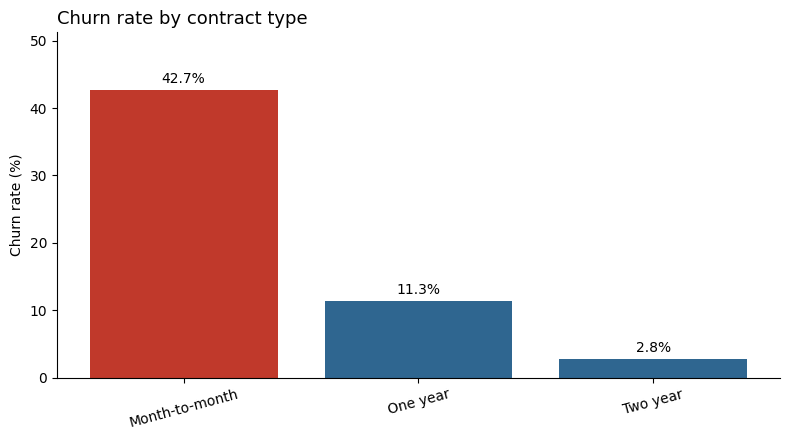

In [7]:
bar_chart(contract, "contract", "churn_rate_pct", "Churn rate by contract type")

**Contract type is the strongest signal.** Month-to-month customers churn at 42.7%, compared with 11.3% on one-year contracts and 2.8% on two-year contracts.

## 5. When in the customer lifecycle does churn happen?

In [8]:
tenure = con.sql("""
-- When in the customer lifecycle does churn happen?
SELECT
    tenure_band,
    COUNT(*) AS customers,
    SUM(churned) AS churned_customers,
    ROUND(100.0 * AVG(churned), 1) AS churn_rate_pct,
    -- share of all churned customers that fall in this band
    ROUND(100.0 * SUM(churned) / (SELECT SUM(churned) FROM customers), 1) AS pct_of_all_churn
FROM customers
GROUP BY tenure_band
ORDER BY MIN(tenure_months);
""").df()
tenure

,tenure_band,customers,churned_customers,churn_rate_pct,pct_of_all_churn
0,0-6 months,1481,784.0,52.9,41.9
1,7-12 months,705,253.0,35.9,13.5
2,13-24 months,1024,294.0,28.7,15.7
3,25-48 months,1594,325.0,20.4,17.4
4,49+ months,2239,213.0,9.5,11.4


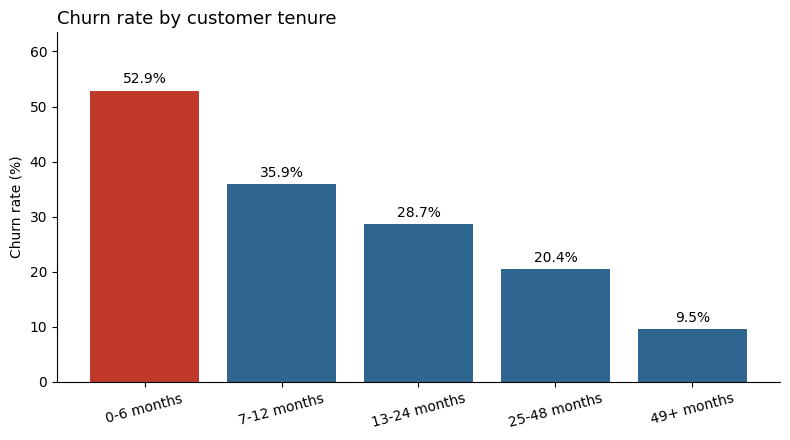

In [9]:
bar_chart(tenure, "tenure_band", "churn_rate_pct", "Churn rate by customer tenure")

**Churn is front-loaded.** Over half of customers in their first six months left (52.9%), and that band alone accounts for 41.9% of all churn. The rate falls steadily with tenure, down to 9.5% for customers past four years.

## 6. Are some payment methods tied to higher churn?

In [10]:
payment = con.sql("""
-- Are some payment methods tied to higher churn?
SELECT
    payment_method,
    COUNT(*) AS customers,
    ROUND(100.0 * AVG(churned), 1) AS churn_rate_pct
FROM customers
GROUP BY payment_method
ORDER BY churn_rate_pct DESC;
""").df()
payment

,payment_method,customers,churn_rate_pct
0,Electronic check,2365,45.3
1,Mailed check,1612,19.1
2,Bank transfer (automatic),1544,16.7
3,Credit card (automatic),1522,15.2


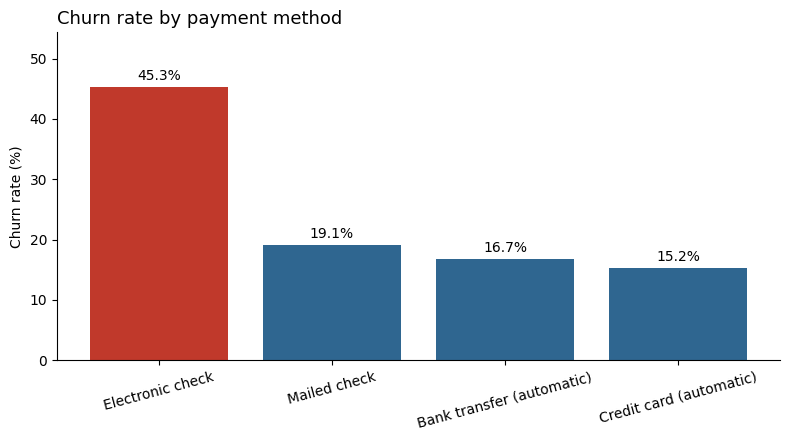

In [11]:
bar_chart(payment, "payment_method", "churn_rate_pct", "Churn rate by payment method")

**Electronic check customers churn at nearly three times the rate of automatic payers:** 45.3%, compared with 15.2% to 16.7% for automatic bank transfer and credit card payments.

## 7. Do support add-ons go with lower churn?

In [12]:
con.sql("""
-- For internet customers, do support add-ons go with lower churn?
SELECT
    internet_service,
    tech_support,
    online_security,
    COUNT(*) AS customers,
    ROUND(100.0 * AVG(churned), 1) AS churn_rate_pct
FROM customers
WHERE internet_service <> 'No'
GROUP BY ALL
HAVING COUNT(*) >= 100
ORDER BY churn_rate_pct DESC;
""").df()

,internet_service,tech_support,online_security,customers,churn_rate_pct
0,Fiber optic,No,No,1765,55.0
1,DSL,No,No,788,35.4
2,Fiber optic,Yes,No,492,29.1
3,Fiber optic,No,Yes,465,28.0
4,DSL,Yes,No,453,15.0
5,DSL,No,Yes,455,14.5
6,Fiber optic,Yes,Yes,374,14.2
7,DSL,Yes,Yes,725,6.3


**Support add-ons go with much lower churn.** Fiber optic customers with neither tech support nor online security churned at 55.0%. With both add-ons, the rate was 14.2%.

## 8. Which group should a retention effort target first?

In [13]:
con.sql("""
-- The segment to target first: new, month-to-month customers paying by electronic check
SELECT
    CASE WHEN contract = 'Month-to-month'
          AND tenure_months <= 12
          AND payment_method = 'Electronic check'
         THEN 'High risk segment' ELSE 'Everyone else' END AS segment,
    COUNT(*) AS customers,
    ROUND(100.0 * AVG(churned), 1) AS churn_rate_pct,
    ROUND(100.0 * SUM(churned) / (SELECT SUM(churned) FROM customers), 1) AS pct_of_all_churn,
    ROUND(SUM(CASE WHEN churned = 1 THEN monthly_charges END), 0) AS churned_monthly_revenue
FROM customers
GROUP BY ALL
ORDER BY segment DESC;
""").df()

,segment,customers,churn_rate_pct,pct_of_all_churn,churned_monthly_revenue
0,High risk segment,954,63.1,32.2,43703.0
1,Everyone else,6089,20.8,67.8,95428.0


**One segment drives a third of all churn.** Customers who are month-to-month, in their first 12 months, and paying by electronic check make up 14% of the customer base (954 customers). They churn at 63.1% and account for 32.2% of all churned customers.

## 9. Recommendations

1. **Target the high-risk segment first.** It's small enough to act on and accounts for a third of the churn.
2. **Offer an incentive to move from month-to-month to an annual contract,** timed within the first six months, before most churn happens.
3. **Encourage switching to automatic payments** with a small discount or a simpler signup at onboarding.
4. **Bundle tech support or online security into early fiber plans,** and test whether it lowers churn for new customers.

These patterns show which groups churn more, not what causes it. An A/B test of each offer would confirm whether it actually changes customer behavior.